In [1]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import time
import json

PROJECT_DIR = Path(
    "/content/drive/MyDrive/customer-churn-intelligence"
)

DATA_DIR = PROJECT_DIR / "data"
NOTEBOOK_DIR = PROJECT_DIR / "notebooks"
ARTIFACT_DIR = PROJECT_DIR / "artifacts"
MODEL_DIR = ARTIFACT_DIR / "models"
CHECKPOINT_DIR = ARTIFACT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"
METRICS_DIR = RESULTS_DIR / "metrics"
FIGURES_DIR = RESULTS_DIR / "figures"
LOGS_DIR = RESULTS_DIR / "logs"

for folder in [
    DATA_DIR,
    NOTEBOOK_DIR,
    MODEL_DIR,
    CHECKPOINT_DIR,
    METRICS_DIR,
    FIGURES_DIR,
    LOGS_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

DATA_PATH = DATA_DIR / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

print("Project directory:", PROJECT_DIR)
print("Dataset exists:", DATA_PATH.exists())
print("Project folders are ready.")

Project directory: /content/drive/MyDrive/customer-churn-intelligence
Dataset exists: True
Project folders are ready.


In [4]:


import pandas as pd
from pathlib import Path

DATA_PATH = Path(
    "/content/drive/MyDrive/customer-churn-intelligence/data/"
    "WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("-" * 40)
print(f"Number of rows    : {df.shape[0]:,}")
print(f"Number of columns : {df.shape[1]}")
print(f"Memory usage      : {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print(f"Target available  : {'Churn' in df.columns}")

Dataset loaded successfully!
----------------------------------------
Number of rows    : 7,043
Number of columns : 21
Memory usage      : 6.82 MB
Target available  : True


In [5]:
print("FIRST 5 ROWS")
display(df.head())

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nDATA TYPES AND NON-NULL COUNTS")
df.info()

FIRST 5 ROWS


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



COLUMN NAMES
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

DATA TYPES AND NON-NULL COUNTS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   O

In [6]:
print("MISSING VALUES")
missing = df.isnull().sum()
print(missing[missing > 0].sort_values(ascending=False))

print("\nDUPLICATE ROWS")
print("Count:", df.duplicated().sum())

print("\nDUPLICATE CUSTOMER IDs")
print("Count:", df["customerID"].duplicated().sum())

print("\nTARGET DISTRIBUTION")
print(df["Churn"].value_counts(dropna=False))

print("\nTARGET DISTRIBUTION (%)")
print(
    df["Churn"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

MISSING VALUES
Series([], dtype: int64)

DUPLICATE ROWS
Count: 0

DUPLICATE CUSTOMER IDs
Count: 0

TARGET DISTRIBUTION
Churn
No     5174
Yes    1869
Name: count, dtype: int64

TARGET DISTRIBUTION (%)
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [7]:


import json
import pandas as pd
from pathlib import Path

# Keep the original dataset unchanged
total_charges_numeric = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

# Find blank and invalid values
blank_mask = df["TotalCharges"].astype(str).str.strip().eq("")
invalid_mask = total_charges_numeric.isna()

invalid_rows = df.loc[invalid_mask].copy()

print("TOTALCHARGES AUDIT")
print("-" * 40)
print("Original dtype:", df["TotalCharges"].dtype)
print("Blank/whitespace entries:", int(blank_mask.sum()))
print("Non-numeric or missing entries:", int(invalid_mask.sum()))
print("Valid numeric entries:", int(total_charges_numeric.notna().sum()))

print("\nRows with invalid TotalCharges:")
display(invalid_rows)

print("\nTenure for invalid rows:")
if not invalid_rows.empty:
    display(invalid_rows[["customerID", "tenure", "TotalCharges", "Churn"]])

# Save the findings to Google Drive
METRICS_DIR.mkdir(parents=True, exist_ok=True)
LOGS_DIR.mkdir(parents=True, exist_ok=True)

audit_summary = {
    "rows": int(df.shape[0]),
    "columns": int(df.shape[1]),
    "duplicate_rows": int(df.duplicated().sum()),
    "duplicate_customer_ids": int(df["customerID"].duplicated().sum()),
    "churn_yes": int(df["Churn"].eq("Yes").sum()),
    "churn_no": int(df["Churn"].eq("No").sum()),
    "churn_rate_percent": round(float(df["Churn"].eq("Yes").mean() * 100), 2),
    "totalcharges_blank_entries": int(blank_mask.sum()),
    "totalcharges_invalid_entries": int(invalid_mask.sum()),
}

with open(METRICS_DIR / "initial_audit.json", "w") as f:
    json.dump(audit_summary, f, indent=2)

if not invalid_rows.empty:
    invalid_rows.to_csv(
        LOGS_DIR / "invalid_totalcharges_rows.csv",
        index=False
    )

print("\nAudit summary saved to:", METRICS_DIR / "initial_audit.json")
print("Audit artifacts saved successfully.")

TOTALCHARGES AUDIT
----------------------------------------
Original dtype: object
Blank/whitespace entries: 11
Non-numeric or missing entries: 11
Valid numeric entries: 7032

Rows with invalid TotalCharges:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No



Tenure for invalid rows:


,customerID,tenure,TotalCharges,Churn
488,4472-LVYGI,0,,No
753,3115-CZMZD,0,,No
936,5709-LVOEQ,0,,No
1082,4367-NUYAO,0,,No
1340,1371-DWPAZ,0,,No
3331,7644-OMVMY,0,,No
3826,3213-VVOLG,0,,No
4380,2520-SGTTA,0,,No
5218,2923-ARZLG,0,,No
6670,4075-WKNIU,0,,No



Audit summary saved to: /content/drive/MyDrive/customer-churn-intelligence/results/metrics/initial_audit.json
Audit artifacts saved successfully.


In [8]:
# Step 11: Clean TotalCharges and save a checkpoint

import json
import pandas as pd
from pathlib import Path

# Preserve df; work on a separate copy
df_clean = df.copy()

# Convert TotalCharges to numeric
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

# Verify the conversion
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape :", df_clean.shape)
print("TotalCharges dtype     :", df_clean["TotalCharges"].dtype)
print("Missing TotalCharges   :", df_clean["TotalCharges"].isna().sum())
print("Zero-tenure rows        :", (df_clean["tenure"] == 0).sum())

# Confirm all newly missing values belong to zero-tenure rows
invalid_mask = df_clean["TotalCharges"].isna()

assert df_clean.loc[invalid_mask, "tenure"].eq(0).all()
assert df_clean.shape == df.shape
assert df_clean["customerID"].equals(df["customerID"])

# Save cleaned data to Google Drive
CLEAN_DATA_PATH = DATA_DIR / "telco_churn_cleaned.csv"
df_clean.to_csv(CLEAN_DATA_PATH, index=False)

# Save the cleaning decision
cleaning_log = {
    "operation": "Convert TotalCharges to numeric",
    "original_rows": int(df.shape[0]),
    "cleaned_rows": int(df_clean.shape[0]),
    "totalcharges_missing_after_conversion": int(
        df_clean["TotalCharges"].isna().sum()
    ),
    "rows_dropped": 0,
    "imputation_performed": False,
    "original_dataset_preserved": True
}

with open(LOGS_DIR / "cleaning_log.json", "w") as f:
    json.dump(cleaning_log, f, indent=2)

print("\nCleaned dataset saved:", CLEAN_DATA_PATH)
print("Cleaning log saved.")
print("No rows dropped; no imputation performed.")

Original dataset shape: (7043, 21)
Cleaned dataset shape : (7043, 21)
TotalCharges dtype     : float64
Missing TotalCharges   : 11
Zero-tenure rows        : 11

Cleaned dataset saved: /content/drive/MyDrive/customer-churn-intelligence/data/telco_churn_cleaned.csv
Cleaning log saved.
No rows dropped; no imputation performed.


In [9]:
# Restore the saved checkpoint
df_clean = pd.read_csv(CLEAN_DATA_PATH)

print("Cleaned dataset restored:", df_clean.shape)
print("TotalCharges dtype:", df_clean["TotalCharges"].dtype)
print("Missing TotalCharges:", df_clean["TotalCharges"].isna().sum())


Cleaned dataset restored: (7043, 21)
TotalCharges dtype: float64
Missing TotalCharges: 11


In [10]:
# Step 12: Validate numerical ranges and categorical values

# 1. Numerical summary
numeric_cols = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

print("NUMERICAL SUMMARY")
display(df_clean[numeric_cols].describe().T)

# 2. Check expected numerical ranges
print("\nRANGE CHECKS")

print("Negative tenure:", (df_clean["tenure"] < 0).sum())
print("Negative MonthlyCharges:", (df_clean["MonthlyCharges"] < 0).sum())
print("Negative TotalCharges:", (df_clean["TotalCharges"] < 0).sum())
print("Unexpected SeniorCitizen values:",
      sorted(set(df_clean["SeniorCitizen"].dropna()) - {0, 1}))

# 3. Inspect categorical values
categorical_cols = df_clean.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("\nUNIQUE CATEGORICAL VALUES")

for col in categorical_cols:
    print(f"\n{col}: {df_clean[col].nunique(dropna=False)} unique values")
    print(df_clean[col].value_counts(dropna=False).to_dict())

# 4. Validate target labels
print("\nTARGET LABEL CHECK")
print("Labels:", sorted(df_clean["Churn"].dropna().unique()))
print("Missing target values:", df_clean["Churn"].isna().sum())

# 5. Check customer ID uniqueness
print("\nIDENTIFIER CHECK")
print("Unique customer IDs:", df_clean["customerID"].nunique())
print("Total rows:", len(df_clean))

NUMERICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.000,0.0000,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80



RANGE CHECKS
Negative tenure: 0
Negative MonthlyCharges: 0
Negative TotalCharges: 0
Unexpected SeniorCitizen values: []

UNIQUE CATEGORICAL VALUES

customerID: 7043 unique values
{'3186-AJIEK': 1, '7590-VHVEG': 1, '5575-GNVDE': 1, '8775-CEBBJ': 1, '2823-LKABH': 1, '7398-LXGYX': 1, '1035-IPQPU': 1, '7203-OYKCT': 1, '1699-HPSBG': 1, '9837-FWLCH': 1, '9710-NJERN': 1, '1122-JWTJW': 1, '4807-IZYOZ': 1, '1471-GIQKQ': 1, '0666-UXTJO': 1, '9053-EJUNL': 1, '1685-BQULA': 1, '6691-CCIHA': 1, '5482-NUPNA': 1, '3413-BMNZE': 1, '7310-EGVHZ': 1, '6827-IEAUQ': 1, '4929-XIHVW': 1, '3841-NFECX': 1, '8773-HHUOZ': 1, '5248-YGIJN': 1, '8665-UTDHZ': 1, '6467-CHFZW': 1, '6865-JZNKO': 1, '6322-HRPFA': 1, '3638-WEABW': 1, '1066-JKSGK': 1, '1680-VDCWW': 1, '8779-QRDMV': 1, '4183-MYFRB': 1, '8012-SOUDQ': 1, '2954-PIBKO': 1, '7639-LIAYI': 1, '7760-OYPDY': 1, '5948-UJZLF': 1, '3714-NTNFO': 1, '4080-IIARD': 1, '4671-VJLCL': 1, '9867-JCZSP': 1, '9489-DEDVP': 1, '8865-TNMNX': 1, '8168-UQWWF': 1, '5380-WJKOV': 1, '65

In [11]:
# Step 13: Compact categorical audit

categorical_cols = [
    col for col in df_clean.select_dtypes(include="object").columns
    if col != "customerID"
]

for col in categorical_cols:
    print(f"\n{col} ({df_clean[col].nunique(dropna=False)} unique values)")
    print(sorted(df_clean[col].dropna().unique().tolist()))

# Verify target labels
expected_target_labels = {"Yes", "No"}
actual_target_labels = set(df_clean["Churn"].dropna().unique())

print("\nTarget labels:", actual_target_labels)
print("Target labels valid:", actual_target_labels == expected_target_labels)
print("Missing target values:", df_clean["Churn"].isna().sum())

# Save compact category audit
category_audit = {
    col: sorted(df_clean[col].dropna().astype(str).unique().tolist())
    for col in categorical_cols
}

category_audit_path = METRICS_DIR / "categorical_audit.json"

with open(category_audit_path, "w") as f:
    json.dump(category_audit, f, indent=2)

print("\nCategory audit saved:", category_audit_path)


gender (2 unique values)
['Female', 'Male']

Partner (2 unique values)
['No', 'Yes']

Dependents (2 unique values)
['No', 'Yes']

PhoneService (2 unique values)
['No', 'Yes']

MultipleLines (3 unique values)
['No', 'No phone service', 'Yes']

InternetService (3 unique values)
['DSL', 'Fiber optic', 'No']

OnlineSecurity (3 unique values)
['No', 'No internet service', 'Yes']

OnlineBackup (3 unique values)
['No', 'No internet service', 'Yes']

DeviceProtection (3 unique values)
['No', 'No internet service', 'Yes']

TechSupport (3 unique values)
['No', 'No internet service', 'Yes']

StreamingTV (3 unique values)
['No', 'No internet service', 'Yes']

StreamingMovies (3 unique values)
['No', 'No internet service', 'Yes']

Contract (3 unique values)
['Month-to-month', 'One year', 'Two year']

PaperlessBilling (2 unique values)
['No', 'Yes']

PaymentMethod (4 unique values)
['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']

Churn (2 unique values)


CHURN BY CONTRACT


,Customers,ChurnRate
Contract,,
Month-to-month,3875,42.71
One year,1473,11.27
Two year,1695,2.83


CHURN BY TENURE


,Customers,ChurnRate
TenureGroup,,
0–12 months,2186,47.44
13–24 months,1024,28.71
25–48 months,1594,20.39
49–72 months,2239,9.51


CHURN BY PAYMENT METHOD


,Customers,ChurnRate
PaymentMethod,,
Electronic check,2365,45.29
Mailed check,1612,19.11
Bank transfer (automatic),1544,16.71
Credit card (automatic),1522,15.24


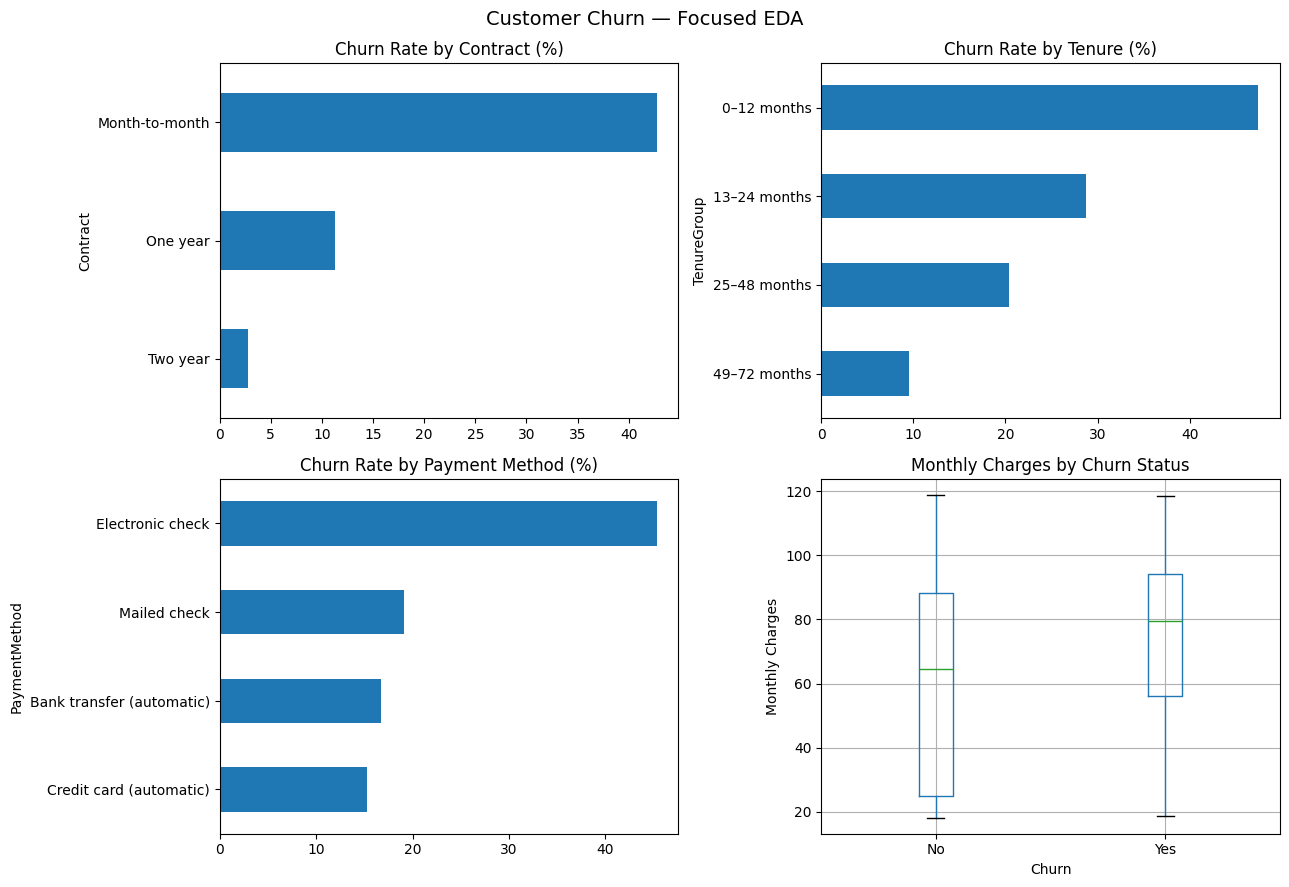

EDA figure saved: /content/drive/MyDrive/customer-churn-intelligence/results/figures/focused_churn_eda.png
EDA summaries saved: /content/drive/MyDrive/customer-churn-intelligence/results/metrics


In [12]:
import matplotlib.pyplot as plt
import pandas as pd
import json

# 1. Prepare concise churn-rate tables
eda_df = df_clean.copy()
eda_df["ChurnFlag"] = (eda_df["Churn"] == "Yes").astype(int)

eda_df["TenureGroup"] = pd.cut(
    eda_df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0–12 months", "13–24 months",
            "25–48 months", "49–72 months"]
)

def churn_summary(column):
    return (
        eda_df.groupby(column, observed=True)
        .agg(
            Customers=("ChurnFlag", "size"),
            ChurnRate=("ChurnFlag", "mean")
        )
        .assign(ChurnRate=lambda x: x["ChurnRate"] * 100)
        .round(2)
        .sort_values("ChurnRate", ascending=False)
    )

contract_summary = churn_summary("Contract")
tenure_summary = churn_summary("TenureGroup")
payment_summary = churn_summary("PaymentMethod")

print("CHURN BY CONTRACT")
display(contract_summary)

print("CHURN BY TENURE")
display(tenure_summary)

print("CHURN BY PAYMENT METHOD")
display(payment_summary)

# 2. Save summary tables
contract_summary.to_csv(METRICS_DIR / "churn_by_contract.csv")
tenure_summary.to_csv(METRICS_DIR / "churn_by_tenure.csv")
payment_summary.to_csv(METRICS_DIR / "churn_by_payment_method.csv")

# 3. Create one compact, four-panel figure
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

contract_summary["ChurnRate"].sort_values().plot(
    kind="barh", ax=axes[0, 0], title="Churn Rate by Contract (%)"
)

tenure_summary["ChurnRate"].sort_values().plot(
    kind="barh", ax=axes[0, 1], title="Churn Rate by Tenure (%)"
)

payment_summary["ChurnRate"].sort_values().plot(
    kind="barh", ax=axes[1, 0], title="Churn Rate by Payment Method (%)"
)

eda_df.boxplot(column="MonthlyCharges", by="Churn", ax=axes[1, 1])
axes[1, 1].set_title("Monthly Charges by Churn Status")
axes[1, 1].set_xlabel("Churn")
axes[1, 1].set_ylabel("Monthly Charges")
fig.suptitle("Customer Churn — Focused EDA", fontsize=14)
plt.tight_layout()

figure_path = FIGURES_DIR / "focused_churn_eda.png"
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

# 4. Save a small analysis checkpoint
eda_checkpoint = {
    "contract_churn": contract_summary.reset_index().to_dict("records"),
    "tenure_churn": tenure_summary.reset_index().to_dict("records"),
    "payment_method_churn": payment_summary.reset_index().to_dict("records"),
    "figure_path": str(figure_path)
}

with open(METRICS_DIR / "focused_eda_summary.json", "w") as f:
    json.dump(eda_checkpoint, f, indent=2)

print("EDA figure saved:", figure_path)
print("EDA summaries saved:", METRICS_DIR)

In [13]:
from sklearn.model_selection import train_test_split
import json

# Start from the saved, cleaned dataset
model_df = df_clean.copy()

# Document the domain-based handling decision
missing_before = int(model_df["TotalCharges"].isna().sum())

assert model_df.loc[
    model_df["TotalCharges"].isna(), "tenure"
].eq(0).all(), "Review missing TotalCharges rows before proceeding."

model_df["TotalCharges"] = model_df["TotalCharges"].fillna(0)

# Separate target and exclude the identifier
X = model_df.drop(columns=["Churn", "customerID"])
y = model_df["Churn"].map({"No": 0, "Yes": 1})

assert y.notna().all()
assert X.shape[0] == y.shape[0]
assert model_df["TotalCharges"].isna().sum() == 0

# 70% train, 15% validation, 15% test
X_train, X_remaining, y_train, y_remaining = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_valid, X_test, y_valid, y_test = train_test_split(
    X_remaining, y_remaining,
    test_size=0.50,
    random_state=42,
    stratify=y_remaining
)

print("Training:", X_train.shape, "| churn rate:", round(y_train.mean(), 4))
print("Validation:", X_valid.shape, "| churn rate:", round(y_valid.mean(), 4))
print("Test:", X_test.shape, "| churn rate:", round(y_test.mean(), 4))
print("Missing TotalCharges before handling:", missing_before)
print("Missing TotalCharges after handling:", model_df["TotalCharges"].isna().sum())
print("Customer ID included in features:", "customerID" in X.columns)

# Save split metadata, not the live variables
split_metadata = {
    "random_state": 42,
    "split_ratio": {"train": 0.70, "validation": 0.15, "test": 0.15},
    "rows": {
        "train": len(X_train),
        "validation": len(X_valid),
        "test": len(X_test)
    },
    "missing_TotalCharges_before": missing_before,
    "missing_TotalCharges_handling": (
        "Filled with 0 because all missing rows have tenure=0; "
        "domain-based assumption, documented for review."
    ),
    "customerID_excluded": True
}

with open(METRICS_DIR / "split_metadata.json", "w") as f:
    json.dump(split_metadata, f, indent=2)

print("Split metadata saved:", METRICS_DIR / "split_metadata.json")

Training: (4930, 19) | churn rate: 0.2653
Validation: (1056, 19) | churn rate: 0.2652
Test: (1057, 19) | churn rate: 0.2658
Missing TotalCharges before handling: 11
Missing TotalCharges after handling: 0
Customer ID included in features: False
Split metadata saved: /content/drive/MyDrive/customer-churn-intelligence/results/metrics/split_metadata.json


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Identify feature types from the training set only
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numeric features:", numeric_features)
print("Number of numeric features:", len(numeric_features))
print("Categorical features:", categorical_features)
print("Number of categorical features:", len(categorical_features))

# Numeric preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing branches
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("\nPreprocessing pipeline created successfully.")
print("No model has been trained yet.")

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Number of numeric features: 4
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Number of categorical features: 15

Preprocessing pipeline created successfully.
No model has been trained yet.


In [15]:
import time
import json
import joblib

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Build the complete model pipeline
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        solver="lbfgs",
        random_state=42
    ))
])

# Fit using training data only
print("Starting Logistic Regression baseline...")
start_time = time.time()

baseline_model.fit(X_train, y_train)

fit_seconds = time.time() - start_time
print(f"Model fitting completed in {fit_seconds:.2f} seconds.")

# Evaluate on validation data
y_valid_pred = baseline_model.predict(X_valid)
y_valid_proba = baseline_model.predict_proba(X_valid)[:, 1]

baseline_metrics = {
    "model": "Logistic Regression",
    "fit_seconds": round(fit_seconds, 2),
    "accuracy": float(accuracy_score(y_valid, y_valid_pred)),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_valid, y_valid_pred)
    ),
    "precision": float(
        precision_score(y_valid, y_valid_pred, zero_division=0)
    ),
    "recall": float(
        recall_score(y_valid, y_valid_pred, zero_division=0)
    ),
    "f1": float(f1_score(y_valid, y_valid_pred, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_valid, y_valid_proba)),
    "confusion_matrix": confusion_matrix(
        y_valid, y_valid_pred
    ).tolist()
}

print("\nVALIDATION METRICS")
for metric, value in baseline_metrics.items():
    print(f"{metric}: {value}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_valid,
    y_valid_pred,
    target_names=["No Churn", "Churn"],
    digits=4,
    zero_division=0
))

# Save the fitted model and metrics to Drive
model_path = MODEL_DIR / "logistic_regression_baseline.joblib"
metrics_path = METRICS_DIR / "logistic_regression_baseline.json"

joblib.dump(baseline_model, model_path)

with open(metrics_path, "w") as f:
    json.dump(baseline_metrics, f, indent=2)

print("\nModel saved:", model_path)
print("Metrics saved:", metrics_path)


Starting Logistic Regression baseline...
Model fitting completed in 0.29 seconds.

VALIDATION METRICS
model: Logistic Regression
fit_seconds: 0.29
accuracy: 0.8058712121212122
balanced_accuracy: 0.7377945508100148
precision: 0.6459143968871596
recall: 0.5928571428571429
f1: 0.6182495344506518
roc_auc: 0.8454321612665685
confusion_matrix: [[685, 91], [114, 166]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    No Churn     0.8573    0.8827    0.8698       776
       Churn     0.6459    0.5929    0.6182       280

    accuracy                         0.8059      1056
   macro avg     0.7516    0.7378    0.7440      1056
weighted avg     0.8013    0.8059    0.8031      1056


Model saved: /content/drive/MyDrive/customer-churn-intelligence/artifacts/models/logistic_regression_baseline.joblib
Metrics saved: /content/drive/MyDrive/customer-churn-intelligence/results/metrics/logistic_regression_baseline.json


In [16]:
import time
import json
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix
)

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

print("Starting Random Forest experiment...")
start_time = time.time()

rf_model.fit(X_train, y_train)

fit_seconds = time.time() - start_time
print(f"Training completed in {fit_seconds:.2f} seconds.")

y_valid_pred_rf = rf_model.predict(X_valid)
y_valid_proba_rf = rf_model.predict_proba(X_valid)[:, 1]

rf_metrics = {
    "model": "Random Forest",
    "fit_seconds": round(fit_seconds, 2),
    "accuracy": float(accuracy_score(y_valid, y_valid_pred_rf)),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_valid, y_valid_pred_rf)
    ),
    "precision": float(
        precision_score(y_valid, y_valid_pred_rf, zero_division=0)
    ),
    "recall": float(
        recall_score(y_valid, y_valid_pred_rf, zero_division=0)
    ),
    "f1": float(f1_score(y_valid, y_valid_pred_rf, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_valid, y_valid_proba_rf)),
    "confusion_matrix": confusion_matrix(
        y_valid, y_valid_pred_rf
    ).tolist()
}

print("\nRANDOM FOREST VALIDATION METRICS")
for metric, value in rf_metrics.items():
    print(f"{metric}: {value}")

rf_model_path = MODEL_DIR / "random_forest_baseline.joblib"
rf_metrics_path = METRICS_DIR / "random_forest_baseline.json"

joblib.dump(rf_model, rf_model_path)

with open(rf_metrics_path, "w") as f:
    json.dump(rf_metrics, f, indent=2)

print("\nModel saved:", rf_model_path)
print("Metrics saved:", rf_metrics_path)

Starting Random Forest experiment...
Training completed in 2.69 seconds.

RANDOM FOREST VALIDATION METRICS
model: Random Forest
fit_seconds: 2.69
accuracy: 0.7670454545454546
balanced_accuracy: 0.763880706921944
precision: 0.5435897435897435
recall: 0.7571428571428571
f1: 0.6328358208955224
roc_auc: 0.8409356590574374
confusion_matrix: [[598, 178], [68, 212]]

Model saved: /content/drive/MyDrive/customer-churn-intelligence/artifacts/models/random_forest_baseline.joblib
Metrics saved: /content/drive/MyDrive/customer-churn-intelligence/results/metrics/random_forest_baseline.json


In [17]:
import pandas as pd
import json
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    balanced_accuracy_score, confusion_matrix
)

threshold_results = []

for threshold in [0.30, 0.40, 0.50, 0.60]:
    predictions = (y_valid_proba_rf >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid, predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_valid, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_valid, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_valid, predictions, zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_valid, predictions
        ),
        "true_positives": int(tp),
        "false_positives": int(fp),
        "true_negatives": int(tn),
        "false_negatives": int(fn)
    })

threshold_df = pd.DataFrame(threshold_results).round(4)
display(threshold_df)

threshold_path = METRICS_DIR / "random_forest_threshold_analysis.csv"
threshold_df.to_csv(threshold_path, index=False)

print("Threshold analysis saved:", threshold_path)

,threshold,precision,recall,f1,balanced_accuracy,true_positives,false_positives,true_negatives,false_negatives
0,0.3,0.4500,0.9000,0.6000,0.7515,252,308,468,28
1,0.4,0.4969,0.8464,0.6262,0.7686,237,240,536,43
2,0.5,0.5436,0.7571,0.6328,0.7639,212,178,598,68
3,0.6,0.5920,0.6321,0.6114,0.7375,177,122,654,103


Threshold analysis saved: /content/drive/MyDrive/customer-churn-intelligence/results/metrics/random_forest_threshold_analysis.csv


In [18]:
retention_summary = threshold_df[
    ["threshold", "true_positives", "false_positives",
     "true_negatives", "false_negatives", "precision", "recall", "f1"]
].copy()

retention_summary["customers_targeted"] = (
    retention_summary["true_positives"]
    + retention_summary["false_positives"]
)

retention_summary["targeted_pct"] = (
    retention_summary["customers_targeted"] / len(y_valid) * 100
).round(2)

retention_summary["churners_captured_pct"] = (
    retention_summary["true_positives"] / y_valid.sum() * 100
).round(2)

display(retention_summary.round(3))

retention_summary.to_csv(
    METRICS_DIR / "retention_targeting_summary.csv",
    index=False
)

print("Saved:", METRICS_DIR / "retention_targeting_summary.csv")

,threshold,true_positives,false_positives,true_negatives,false_negatives,precision,recall,f1,customers_targeted,targeted_pct,churners_captured_pct
0,0.3,252,308,468,28,0.450,0.900,0.600,560,53.03,90.00
1,0.4,237,240,536,43,0.497,0.846,0.626,477,45.17,84.64
2,0.5,212,178,598,68,0.544,0.757,0.633,390,36.93,75.71
3,0.6,177,122,654,103,0.592,0.632,0.611,299,28.31,63.21


Saved: /content/drive/MyDrive/customer-churn-intelligence/results/metrics/retention_targeting_summary.csv


In [19]:
import time
import json
import joblib

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix
)

gb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=2,
        random_state=42
    ))
])

print("Starting Gradient Boosting experiment...")
start_time = time.time()

gb_model.fit(X_train, y_train)

fit_seconds = time.time() - start_time
print(f"Training completed in {fit_seconds:.2f} seconds.")

y_valid_pred_gb = gb_model.predict(X_valid)
y_valid_proba_gb = gb_model.predict_proba(X_valid)[:, 1]

gb_metrics = {
    "model": "Gradient Boosting",
    "fit_seconds": round(fit_seconds, 2),
    "accuracy": float(accuracy_score(y_valid, y_valid_pred_gb)),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_valid, y_valid_pred_gb)
    ),
    "precision": float(
        precision_score(y_valid, y_valid_pred_gb, zero_division=0)
    ),
    "recall": float(
        recall_score(y_valid, y_valid_pred_gb, zero_division=0)
    ),
    "f1": float(f1_score(y_valid, y_valid_pred_gb, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_valid, y_valid_proba_gb)),
    "confusion_matrix": confusion_matrix(
        y_valid, y_valid_pred_gb
    ).tolist()
}

print("\nGRADIENT BOOSTING VALIDATION METRICS")
for metric, value in gb_metrics.items():
    print(f"{metric}: {value}")

gb_model_path = MODEL_DIR / "gradient_boosting_baseline.joblib"
gb_metrics_path = METRICS_DIR / "gradient_boosting_baseline.json"

joblib.dump(gb_model, gb_model_path)

with open(gb_metrics_path, "w") as f:
    json.dump(gb_metrics, f, indent=2)

print("\nModel saved:", gb_model_path)
print("Metrics saved:", gb_metrics_path)

Starting Gradient Boosting experiment...
Training completed in 1.84 seconds.

GRADIENT BOOSTING VALIDATION METRICS
model: Gradient Boosting
fit_seconds: 1.84
accuracy: 0.8039772727272727
balanced_accuracy: 0.7136782032400589
precision: 0.6666666666666666
recall: 0.5214285714285715
f1: 0.5851703406813628
roc_auc: 0.8522275405007363
confusion_matrix: [[703, 73], [134, 146]]

Model saved: /content/drive/MyDrive/customer-churn-intelligence/artifacts/models/gradient_boosting_baseline.joblib
Metrics saved: /content/drive/MyDrive/customer-churn-intelligence/results/metrics/gradient_boosting_baseline.json


In [20]:
# Install only if CatBoost is not already available
try:
    from catboost import CatBoostClassifier
except ImportError:
    %pip -q install catboost
    from catboost import CatBoostClassifier

import time
import json
import joblib

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Identify categorical features by column name
cat_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Categorical features:", len(cat_features))
print(cat_features)

catboost_model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=100,
    early_stopping_rounds=50,
    allow_writing_files=False,
    thread_count=-1
)

print("\nStarting CatBoost experiment...")
start_time = time.time()

catboost_model.fit(
    X_train,
    y_train,
    cat_features=cat_features,
    eval_set=(X_valid, y_valid),
    use_best_model=True,
    verbose=100
)

fit_seconds = time.time() - start_time

print(f"\nTraining completed in {fit_seconds:.2f} seconds.")
print("Best iteration:", catboost_model.get_best_iteration())
print("Best validation score:", catboost_model.get_best_score())

# Evaluate at the default 0.5 threshold
y_valid_proba_cat = catboost_model.predict_proba(X_valid)[:, 1]
y_valid_pred_cat = (y_valid_proba_cat >= 0.5).astype(int)

catboost_metrics = {
    "model": "CatBoost",
    "fit_seconds": round(fit_seconds, 2),
    "best_iteration": int(catboost_model.get_best_iteration()),
    "accuracy": float(accuracy_score(y_valid, y_valid_pred_cat)),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_valid, y_valid_pred_cat)
    ),
    "precision": float(
        precision_score(y_valid, y_valid_pred_cat, zero_division=0)
    ),
    "recall": float(
        recall_score(y_valid, y_valid_pred_cat, zero_division=0)
    ),
    "f1": float(f1_score(y_valid, y_valid_pred_cat, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_valid, y_valid_proba_cat)),
    "confusion_matrix": confusion_matrix(
        y_valid, y_valid_pred_cat
    ).tolist()
}

print("\nCATBOOST VALIDATION METRICS")
for metric, value in catboost_metrics.items():
    print(f"{metric}: {value}")

catboost_model_path = MODEL_DIR / "catboost_baseline.cbm"
catboost_metrics_path = METRICS_DIR / "catboost_baseline.json"

catboost_model.save_model(str(catboost_model_path))

with open(catboost_metrics_path, "w") as f:
    json.dump(catboost_metrics, f, indent=2)

print("\nModel saved:", catboost_model_path)
print("Metrics saved:", catboost_metrics_path)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.0 MB/s eta 0:00:00
Categorical features: 15
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Starting CatBoost experiment...
0:	test: 0.8444404	best: 0.8444404 (0)	total: 82.8ms	remaining: 41.3s
100:	test: 0.8500897	best: 0.8501565 (81)	total: 2.41s	remaining: 9.52s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.850400405
bestIteration = 104

Shrink model to first 105 iterations.

Training completed in 3.72 seconds.
Best iteration: 104
Best validation score: {'learn': {'Logloss': 0.3756623802268056}, 'validation': {'Logloss': 0.41196711596441127, 'AUC': 0.8504004050073638}}

CATBOOST VALIDATION METRICS
model: CatBoost
fit_seconds: 3.72
best_iteration: 104
accuracy: 0.8087121212121212
balanced_accuracy: 0.72260677466863

In [21]:
import pandas as pd
import json

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)

models_to_compare = {
    "Random Forest": y_valid_proba_rf,
    "CatBoost": y_valid_proba_cat
}

threshold_results_all = []

for model_name, probabilities in models_to_compare.items():
    for threshold in [0.30, 0.40, 0.50, 0.60]:
        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_valid, predictions, labels=[0, 1]
        ).ravel()

        threshold_results_all.append({
            "model": model_name,
            "threshold": threshold,
            "precision": precision_score(
                y_valid, predictions, zero_division=0
            ),
            "recall": recall_score(
                y_valid, predictions, zero_division=0
            ),
            "f1": f1_score(
                y_valid, predictions, zero_division=0
            ),
            "balanced_accuracy": balanced_accuracy_score(
                y_valid, predictions
            ),
            "customers_targeted": int(tp + fp),
            "true_positives": int(tp),
            "false_positives": int(fp),
            "false_negatives": int(fn)
        })

threshold_comparison = pd.DataFrame(threshold_results_all)

display(
    threshold_comparison.round(4).sort_values(
        ["model", "threshold"]
    )
)

comparison_path = METRICS_DIR / "rf_vs_catboost_thresholds.csv"
threshold_comparison.to_csv(comparison_path, index=False)

print("Comparison saved:", comparison_path)

,model,threshold,precision,recall,f1,balanced_accuracy,customers_targeted,true_positives,false_positives,false_negatives
4,CatBoost,0.3,0.5354,0.8107,0.6449,0.7784,424,227,197,53
5,CatBoost,0.4,0.5851,0.6750,0.6269,0.7512,323,189,134,91
6,CatBoost,0.5,0.6741,0.5393,0.5992,0.7226,224,151,73,129
7,CatBoost,0.6,0.7293,0.3464,0.4697,0.6500,133,97,36,183
0,Random Forest,0.3,0.4500,0.9000,0.6000,0.7515,560,252,308,28
1,Random Forest,0.4,0.4969,0.8464,0.6262,0.7686,477,237,240,43
2,Random Forest,0.5,0.5436,0.7571,0.6328,0.7639,390,212,178,68
3,Random Forest,0.6,0.5920,0.6321,0.6114,0.7375,299,177,122,103


Comparison saved: /content/drive/MyDrive/customer-churn-intelligence/results/metrics/rf_vs_catboost_thresholds.csv


TOP 15 FEATURES


,Feature,Importance
14,Contract,23.545
4,tenure,13.884
7,InternetService,11.381
18,TotalCharges,6.641
8,OnlineSecurity,6.156
11,TechSupport,5.169
17,MonthlyCharges,4.933
12,StreamingTV,4.868
15,PaperlessBilling,4.568
16,PaymentMethod,4.125


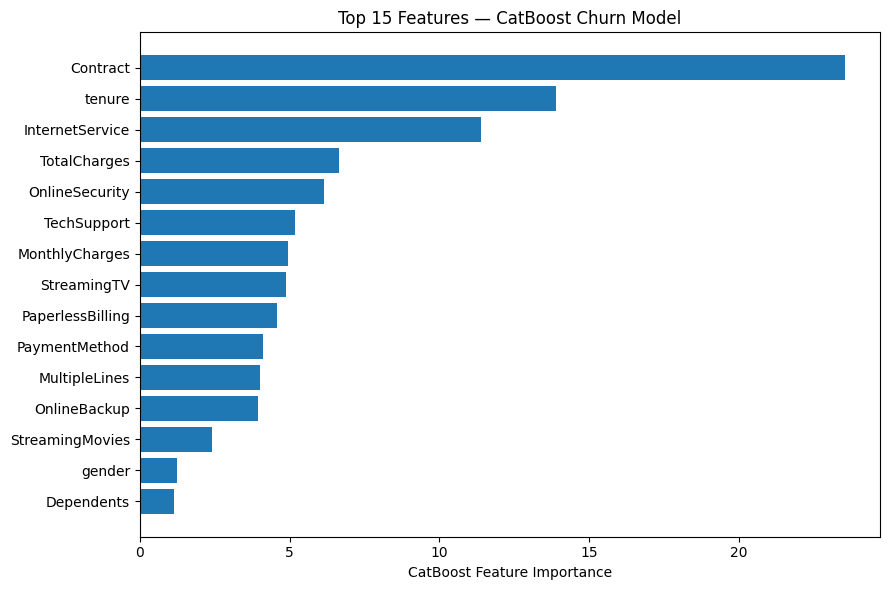

Feature importance saved: /content/drive/MyDrive/customer-churn-intelligence/results/metrics/catboost_feature_importance.csv
Figure saved: /content/drive/MyDrive/customer-churn-intelligence/results/figures/catboost_feature_importance.png


In [22]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract importance from the fitted CatBoost model
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": catboost_model.get_feature_importance()
}).sort_values("Importance", ascending=False)

print("TOP 15 FEATURES")
display(importance_df.head(15).round(3))

# Save all feature importance scores
importance_path = METRICS_DIR / "catboost_feature_importance.csv"
importance_df.to_csv(importance_path, index=False)

# Save a compact visualization
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("CatBoost Feature Importance")
plt.title("Top 15 Features — CatBoost Churn Model")
plt.tight_layout()

importance_figure_path = FIGURES_DIR / "catboost_feature_importance.png"
plt.savefig(importance_figure_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close()

print("Feature importance saved:", importance_path)
print("Figure saved:", importance_figure_path)


Rows selected for SHAP: 200

TOP 15 FEATURES BY MEAN ABSOLUTE SHAP


,Feature,MeanAbsSHAP
14,Contract,0.5941
7,InternetService,0.4437
4,tenure,0.4052
8,OnlineSecurity,0.2183
11,TechSupport,0.1798
16,PaymentMethod,0.1592
12,StreamingTV,0.1371
18,TotalCharges,0.1351
15,PaperlessBilling,0.1298
17,MonthlyCharges,0.1230


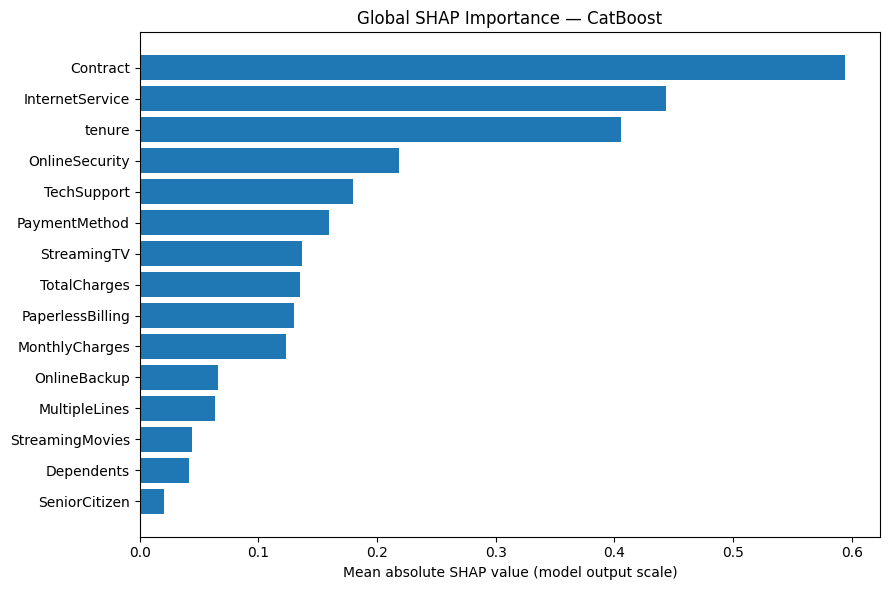


SHAP importance saved: /content/drive/MyDrive/customer-churn-intelligence/results/metrics/catboost_shap_importance.csv
SHAP plot saved: /content/drive/MyDrive/customer-churn-intelligence/results/figures/catboost_shap_importance.png


In [23]:
%pip -q install shap

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Explain a bounded sample of validation customers
X_explain = X_valid.sample(
    n=min(200, len(X_valid)),
    random_state=42
).copy()

print("Rows selected for SHAP:", len(X_explain))

# CatBoost's native SHAP implementation
shap_values = catboost_model.get_feature_importance(
    data=__import__("catboost").Pool(
        X_explain,
        cat_features=cat_features
    ),
    type="ShapValues"
)

# Last column is the expected/base value
shap_contributions = shap_values[:, :-1]
base_values = shap_values[:, -1]

shap_importance = pd.DataFrame({
    "Feature": X_explain.columns,
    "MeanAbsSHAP": np.abs(shap_contributions).mean(axis=0)
}).sort_values("MeanAbsSHAP", ascending=False)

print("\nTOP 15 FEATURES BY MEAN ABSOLUTE SHAP")
display(shap_importance.head(15).round(4))

# Save SHAP importance
shap_importance_path = METRICS_DIR / "catboost_shap_importance.csv"
shap_importance.to_csv(shap_importance_path, index=False)

# Global importance plot
top = shap_importance.head(15).sort_values("MeanAbsSHAP")

plt.figure(figsize=(9, 6))
plt.barh(top["Feature"], top["MeanAbsSHAP"])
plt.xlabel("Mean absolute SHAP value (model output scale)")
plt.title("Global SHAP Importance — CatBoost")
plt.tight_layout()

shap_plot_path = FIGURES_DIR / "catboost_shap_importance.png"
plt.savefig(shap_plot_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close()

print("\nSHAP importance saved:", shap_importance_path)
print("SHAP plot saved:", shap_plot_path)

In [25]:
import pandas as pd

# Reuse existing SHAP results
shap_df = pd.DataFrame(
    shap_contributions,
    columns=X_explain.columns,
    index=X_explain.index
)

# Categorical feature summaries
features_to_analyze = [
    "Contract",
    "InternetService",
    "OnlineSecurity",
    "TechSupport",
    "PaymentMethod"
]

direction_tables = []

for feature in features_to_analyze:
    temp = pd.DataFrame({
        "Feature": feature,
        "Category": X_explain[feature].astype(str).values,
        "SHAP": shap_df[feature].values
    })

    grouped = (
        temp.groupby(["Feature", "Category"])
        .agg(
            Customers=("SHAP", "size"),
            Mean_SHAP=("SHAP", "mean"),
            Mean_Absolute_SHAP=("SHAP", lambda s: s.abs().mean())
        )
        .reset_index()
    )

    direction_tables.append(grouped)

categorical_direction = pd.concat(
    direction_tables, ignore_index=True
)

# Tenure grouped analysis
tenure_direction = pd.DataFrame({
    "Tenure": X_explain["tenure"].values,
    "SHAP": shap_df["tenure"].values
})

tenure_direction["Category"] = pd.cut(
    tenure_direction["Tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "0–12 months",
        "13–24 months",
        "25–48 months",
        "49–72 months"
    ]
)

tenure_summary = (
    tenure_direction.groupby("Category", observed=True)
    .agg(
        Customers=("SHAP", "size"),
        Mean_SHAP=("SHAP", "mean"),
        Mean_Absolute_SHAP=("SHAP", lambda s: s.abs().mean())
    )
    .reset_index()
)

tenure_summary["Feature"] = "tenure"
tenure_summary = tenure_summary.rename(
    columns={"Category": "Category"}
)

# Save both results
categorical_path = METRICS_DIR / "shap_directional_analysis.csv"
tenure_path = METRICS_DIR / "shap_directional_tenure.csv"

categorical_direction.to_csv(categorical_path, index=False)
tenure_summary.to_csv(tenure_path, index=False)

print("CATEGORICAL SHAP DIRECTION")
display(categorical_direction.round(4))

print("TENURE SHAP DIRECTION")
display(tenure_summary.round(4))

print("\nSaved:", categorical_path)
print("Saved:", tenure_path)

CATEGORICAL SHAP DIRECTION


,Feature,Category,Customers,Mean_SHAP,Mean_Absolute_SHAP
0,Contract,Month-to-month,107,0.5585,0.5585
1,Contract,One year,47,-0.4956,0.4956
2,Contract,Two year,46,-0.7777,0.7777
3,InternetService,DSL,69,-0.3260,0.3260
4,InternetService,Fiber optic,89,0.5279,0.5279
5,InternetService,No,42,-0.4589,0.4589
6,OnlineSecurity,No,102,0.2418,0.2418
7,OnlineSecurity,No internet service,42,-0.1811,0.1811
8,OnlineSecurity,Yes,56,-0.2032,0.2032
9,TechSupport,No,83,0.1888,0.1888


TENURE SHAP DIRECTION


,Category,Customers,Mean_SHAP,Mean_Absolute_SHAP,Feature
0,0–12 months,59,0.6609,0.6609,tenure
1,13–24 months,31,-0.0459,0.0648,tenure
2,25–48 months,48,-0.2542,0.2542,tenure
3,49–72 months,62,-0.4488,0.4488,tenure



Saved: /content/drive/MyDrive/customer-churn-intelligence/results/metrics/shap_directional_analysis.csv
Saved: /content/drive/MyDrive/customer-churn-intelligence/results/metrics/shap_directional_tenure.csv


In [26]:
import numpy as np
import pandas as pd

# Use the existing CatBoost model and SHAP sample
customer_risk = X_explain.copy()

customer_risk["Actual_Churn"] = y_valid.loc[X_explain.index].values
customer_risk["Churn_Probability"] = (
    catboost_model.predict_proba(X_explain)[:, 1]
)

# Use 0.30 as our current candidate threshold, not a final decision
customer_risk["Predicted_Churn"] = (
    customer_risk["Churn_Probability"] >= 0.30
).astype(int)

# Transparent operational risk bands
customer_risk["Risk_Segment"] = pd.cut(
    customer_risk["Churn_Probability"],
    bins=[-0.001, 0.30, 0.60, 1.001],
    labels=["Low", "Medium", "High"]
)

# Explain each customer's strongest positive and negative contributions
feature_names = list(X_explain.columns)

explanation_rows = []

for row_position, (customer_index, contributions) in enumerate(
    zip(X_explain.index, shap_contributions)
):
    contribution_series = pd.Series(
        contributions,
        index=feature_names
    )

    strongest_positive = contribution_series.nlargest(3)
    strongest_negative = contribution_series.nsmallest(3)

    explanation_rows.append({
        "Validation_Row_Index": customer_index,
        "Churn_Probability": customer_risk.loc[
            customer_index, "Churn_Probability"
        ],
        "Risk_Segment": str(customer_risk.loc[
            customer_index, "Risk_Segment"
        ]),
        "Top_Risk_Drivers": "; ".join(
            f"{feature} ({value:+.3f})"
            for feature, value in strongest_positive.items()
        ),
        "Top_Risk_Reducing_Factors": "; ".join(
            f"{feature} ({value:+.3f})"
            for feature, value in strongest_negative.items()
        )
    })

explanations_df = pd.DataFrame(explanation_rows)

# Combine risk and explanation outputs
risk_output = customer_risk.reset_index(names="Validation_Row_Index")
risk_output = risk_output.merge(
    explanations_df,
    on=["Validation_Row_Index", "Churn_Probability", "Risk_Segment"],
    how="left"
)

# Save validation risk profiles
risk_path = RESULTS_DIR / "customer_risk_profiles_validation.csv"
risk_output.to_csv(risk_path, index=False)

# Save segment summary
risk_summary = (
    risk_output.groupby("Risk_Segment", observed=True)
    .agg(
        Customers=("Churn_Probability", "size"),
        Mean_Churn_Probability=("Churn_Probability", "mean"),
        Actual_Churn_Rate=("Actual_Churn", "mean"),
        Predicted_Churn_Count=("Predicted_Churn", "sum")
    )
    .reset_index()
)

risk_summary_path = METRICS_DIR / "validation_risk_segment_summary.csv"
risk_summary.to_csv(risk_summary_path, index=False)

print("RISK SEGMENT SUMMARY")
display(risk_summary.round(4))

print("\nSAMPLE CUSTOMER EXPLANATIONS")
display(
    risk_output[
        [
            "Churn_Probability",
            "Risk_Segment",
            "Top_Risk_Drivers",
            "Top_Risk_Reducing_Factors"
        ]
    ].head(10)
)

print("\nRisk profiles saved:", risk_path)
print("Segment summary saved:", risk_summary_path)


RISK SEGMENT SUMMARY


,Risk_Segment,Customers,Mean_Churn_Probability,Actual_Churn_Rate,Predicted_Churn_Count
0,High,28,0.7303,0.7857,28
1,Low,125,0.0986,0.0800,0
2,Medium,47,0.4460,0.4894,47



SAMPLE CUSTOMER EXPLANATIONS


,Churn_Probability,Risk_Segment,Top_Risk_Drivers,Top_Risk_Reducing_Factors
0,0.062424,Low,Contract (+0.773); PaymentMethod (+0.185); gen...,InternetService (-0.456); StreamingTV (-0.344)...
1,0.019662,Low,gender (+0.005); PhoneService (+0.001); Senior...,InternetService (-0.480); Contract (-0.447); S...
2,0.008093,Low,MultipleLines (+0.029); StreamingMovies (+0.01...,Contract (-0.755); tenure (-0.626); InternetSe...
3,0.800711,High,tenure (+0.962); InternetService (+0.588); Tot...,PaperlessBilling (-0.189); MultipleLines (-0.0...
4,0.473113,Medium,Contract (+0.516); InternetService (+0.503); M...,TechSupport (-0.184); OnlineSecurity (-0.166);...
5,0.188227,Low,InternetService (+0.535); PaymentMethod (+0.27...,Contract (-0.597); tenure (-0.246); PaperlessB...
6,0.875625,High,tenure (+0.950); InternetService (+0.594); Con...,StreamingMovies (-0.090); SeniorCitizen (-0.01...
7,0.714319,High,tenure (+0.627); InternetService (+0.542); Con...,MonthlyCharges (-0.099); StreamingMovies (-0.0...
8,0.055417,Low,Contract (+0.790); PhoneService (-0.000); gend...,InternetService (-0.454); tenure (-0.313); Str...
9,0.121261,Low,Contract (+0.657); tenure (+0.545); TotalCharg...,InternetService (-0.433); StreamingTV (-0.332)...



Risk profiles saved: /content/drive/MyDrive/customer-churn-intelligence/results/customer_risk_profiles_validation.csv
Segment summary saved: /content/drive/MyDrive/customer-churn-intelligence/results/metrics/validation_risk_segment_summary.csv


In [28]:
import time
import json
import pandas as pd
import numpy as np

from catboost import CatBoostClassifier
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    accuracy_score
)

# 12 deliberately selected configurations
configurations = [
    {"depth": 5, "learning_rate": 0.03, "l2_leaf_reg": 3},
    {"depth": 5, "learning_rate": 0.03, "l2_leaf_reg": 5},
    {"depth": 5, "learning_rate": 0.05, "l2_leaf_reg": 3},
    {"depth": 5, "learning_rate": 0.05, "l2_leaf_reg": 5},

    {"depth": 6, "learning_rate": 0.03, "l2_leaf_reg": 3},
    {"depth": 6, "learning_rate": 0.03, "l2_leaf_reg": 5},
    {"depth": 6, "learning_rate": 0.05, "l2_leaf_reg": 3},
    {"depth": 6, "learning_rate": 0.08, "l2_leaf_reg": 5},

    {"depth": 8, "learning_rate": 0.03, "l2_leaf_reg": 3},
    {"depth": 8, "learning_rate": 0.03, "l2_leaf_reg": 5},
    {"depth": 8, "learning_rate": 0.05, "l2_leaf_reg": 3},
    {"depth": 8, "learning_rate": 0.08, "l2_leaf_reg": 5},
]

MAX_ITERATIONS = 800
EARLY_STOPPING_ROUNDS = 80
DECISION_THRESHOLD = 0.30

tuning_results = []
best_auc = -np.inf
best_model = None
best_config = None

tuning_start = time.time()

results_path = METRICS_DIR / "catboost_tuning_results.csv"
best_model_path = MODEL_DIR / "catboost_tuned_candidate.cbm"
best_config_path = MODEL_DIR / "catboost_tuned_config.json"

print(f"Starting CatBoost tuning: {len(configurations)} configurations")
print(f"Maximum iterations per fit: {MAX_ITERATIONS}")
print(f"Early stopping rounds: {EARLY_STOPPING_ROUNDS}")
print("-" * 65)

for run_number, config in enumerate(configurations, start=1):
    run_start = time.time()

    model = CatBoostClassifier(
        iterations=MAX_ITERATIONS,
        depth=config["depth"],
        learning_rate=config["learning_rate"],
        l2_leaf_reg=config["l2_leaf_reg"],
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=42,
        early_stopping_rounds=EARLY_STOPPING_ROUNDS,
        verbose=False,
        allow_writing_files=False,
        thread_count=-1
    )

    model.fit(
        X_train,
        y_train,
        cat_features=cat_features,
        eval_set=(X_valid, y_valid),
        use_best_model=True,
        verbose=False
    )

    probabilities = model.predict_proba(X_valid)[:, 1]
    predictions = (probabilities >= DECISION_THRESHOLD).astype(int)

    validation_auc = roc_auc_score(y_valid, probabilities)

    result = {
        "run": run_number,
        **config,
        "best_iteration": int(model.get_best_iteration()),
        "fit_seconds": round(time.time() - run_start, 2),
        "validation_roc_auc": float(validation_auc),
        "validation_f1_at_030": float(
            f1_score(y_valid, predictions, zero_division=0)
        ),
        "validation_recall_at_030": float(
            recall_score(y_valid, predictions, zero_division=0)
        ),
        "validation_precision_at_030": float(
            precision_score(y_valid, predictions, zero_division=0)
        ),
        "validation_balanced_accuracy_at_030": float(
            balanced_accuracy_score(y_valid, predictions)
        ),
        "validation_accuracy_at_030": float(
            accuracy_score(y_valid, predictions)
        )
    }

    tuning_results.append(result)

    # Save every completed run, not just the final result
    results_df = pd.DataFrame(tuning_results)
    results_df.to_csv(results_path, index=False)

    # Primary selection criterion: validation ROC-AUC
    if validation_auc > best_auc:
        best_auc = validation_auc
        best_model = model
        best_config = result.copy()

        best_model.save_model(str(best_model_path))

        with open(best_config_path, "w") as f:
            json.dump(best_config, f, indent=2)

        print(f"  New best validation AUC: {best_auc:.5f}")
        print(f"  Best model checkpoint saved.")

    elapsed = time.time() - tuning_start

    print(
        f"Run {run_number:02d}/{len(configurations)} | "
        f"depth={config['depth']} | "
        f"lr={config['learning_rate']} | "
        f"L2={config['l2_leaf_reg']} | "
        f"AUC={validation_auc:.5f} | "
        f"F1@0.30={result['validation_f1_at_030']:.4f} | "
        f"best_iter={result['best_iteration']} | "
        f"run_time={result['fit_seconds']:.2f}s | "
        f"elapsed={elapsed:.1f}s"
    )

print("\nTUNING COMPLETED")
print(f"Total elapsed time: {time.time() - tuning_start:.2f} seconds")

# Show and save ranked results
tuning_results_df = pd.DataFrame(tuning_results)
tuning_results_df = tuning_results_df.sort_values(
    "validation_roc_auc", ascending=False
).reset_index(drop=True)

print("\nTOP CONFIGURATIONS BY VALIDATION ROC-AUC")
display(
    tuning_results_df[
        [
            "run", "depth", "learning_rate", "l2_leaf_reg",
            "best_iteration", "validation_roc_auc",
            "validation_f1_at_030",
            "validation_recall_at_030",
            "validation_precision_at_030",
            "fit_seconds"
        ]
    ].head(12).round(4)
)

print("\nAll results saved:", results_path)
print("Best candidate saved:", best_model_path)
print("Best configuration saved:", best_config_path)

Starting CatBoost tuning: 12 configurations
Maximum iterations per fit: 800
Early stopping rounds: 80
-----------------------------------------------------------------
  New best validation AUC: 0.84850
  Best model checkpoint saved.
Run 01/12 | depth=5 | lr=0.03 | L2=3 | AUC=0.84850 | F1@0.30=0.6361 | best_iter=87 | run_time=3.71s | elapsed=3.8s
  New best validation AUC: 0.84994
  Best model checkpoint saved.
Run 02/12 | depth=5 | lr=0.03 | L2=5 | AUC=0.84994 | F1@0.30=0.6355 | best_iter=60 | run_time=4.52s | elapsed=8.4s
  New best validation AUC: 0.85140
  Best model checkpoint saved.
Run 03/12 | depth=5 | lr=0.05 | L2=3 | AUC=0.85140 | F1@0.30=0.6384 | best_iter=175 | run_time=4.23s | elapsed=12.7s
Run 04/12 | depth=5 | lr=0.05 | L2=5 | AUC=0.85045 | F1@0.30=0.6456 | best_iter=195 | run_time=3.31s | elapsed=16.0s
Run 05/12 | depth=6 | lr=0.03 | L2=3 | AUC=0.84790 | F1@0.30=0.6137 | best_iter=30 | run_time=1.65s | elapsed=17.7s
Run 06/12 | depth=6 | lr=0.03 | L2=5 | AUC=0.85079 | F

,run,depth,learning_rate,l2_leaf_reg,best_iteration,validation_roc_auc,validation_f1_at_030,validation_recall_at_030,validation_precision_at_030,fit_seconds
0,8,6,0.08,5,75,0.8518,0.6514,0.8107,0.5444,2.66
1,3,5,0.05,3,175,0.8514,0.6384,0.8071,0.5280,4.23
2,6,6,0.03,5,37,0.8508,0.6275,0.8571,0.4948,1.74
3,4,5,0.05,5,195,0.8505,0.6456,0.8036,0.5396,3.31
4,7,6,0.05,3,104,0.8504,0.6449,0.8107,0.5354,4.19
5,2,5,0.03,5,60,0.8499,0.6355,0.8250,0.5168,4.52
6,10,8,0.03,5,25,0.8487,0.5988,0.8929,0.4505,2.60
7,9,8,0.03,3,3,0.8486,0.4192,1.0000,0.2652,2.13
8,1,5,0.03,3,87,0.8485,0.6361,0.8179,0.5205,3.71
9,5,6,0.03,3,30,0.8479,0.6137,0.8821,0.4705,1.65



All results saved: /content/drive/MyDrive/customer-churn-intelligence/results/metrics/catboost_tuning_results.csv
Best candidate saved: /content/drive/MyDrive/customer-churn-intelligence/artifacts/models/catboost_tuned_candidate.cbm
Best configuration saved: /content/drive/MyDrive/customer-churn-intelligence/artifacts/models/catboost_tuned_config.json


In [29]:
import pandas as pd
import numpy as np

from catboost import CatBoostClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    accuracy_score,
    confusion_matrix
)

# Load the saved tuned candidate from Google Drive
tuned_catboost = CatBoostClassifier()
tuned_catboost.load_model(str(MODEL_DIR / "catboost_tuned_candidate.cbm"))

# Generate validation probabilities only
y_valid_array = np.asarray(y_valid)
valid_probabilities = tuned_catboost.predict_proba(X_valid)[:, 1]

thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
threshold_results = []

for threshold in thresholds:
    predictions = (valid_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid_array, predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_valid_array, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_valid_array, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_valid_array, predictions, zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_valid_array, predictions
        ),
        "accuracy": accuracy_score(y_valid_array, predictions),
        "true_positives": int(tp),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_negatives": int(tn),
        "customers_targeted": int(predictions.sum()),
        "targeted_percentage": 100 * predictions.mean()
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_path = METRICS_DIR / "tuned_catboost_threshold_analysis.csv"
threshold_df.to_csv(threshold_path, index=False)

display(threshold_df.round(4))
print("Saved to:", threshold_path)

,threshold,precision,recall,f1,balanced_accuracy,accuracy,true_positives,false_positives,false_negatives,true_negatives,customers_targeted,targeted_percentage
0,0.20,0.4737,0.8679,0.6129,0.7600,0.7093,243,270,37,506,513,48.5795
1,0.25,0.5074,0.8571,0.6375,0.7784,0.7415,240,233,40,543,473,44.7917
2,0.30,0.5444,0.8107,0.6514,0.7829,0.7699,227,190,53,586,417,39.4886
3,0.35,0.5625,0.7393,0.6389,0.7659,0.7784,207,161,73,615,368,34.8485
4,0.40,0.6049,0.7000,0.6490,0.7675,0.7992,196,128,84,648,324,30.6818
5,0.45,0.6269,0.6000,0.6131,0.7356,0.7992,168,100,112,676,268,25.3788
6,0.50,0.6791,0.5214,0.5899,0.7163,0.8078,146,69,134,707,215,20.3598


Saved to: /content/drive/MyDrive/customer-churn-intelligence/results/metrics/tuned_catboost_threshold_analysis.csv


In [30]:
import json
import time
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
from catboost import CatBoostClassifier

# Load the already-selected model from Google Drive
final_model = CatBoostClassifier()
final_model.load_model(str(MODEL_DIR / "catboost_tuned_candidate.cbm"))

FINAL_THRESHOLD = 0.30

# One-time final evaluation on the untouched test set
test_probabilities = final_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= FINAL_THRESHOLD).astype(int)

test_auc = roc_auc_score(y_test, test_probabilities)
test_metrics = {
    "model": "Tuned CatBoost",
    "selected_threshold": FINAL_THRESHOLD,
    "test_accuracy": float(accuracy_score(y_test, test_predictions)),
    "test_balanced_accuracy": float(
        balanced_accuracy_score(y_test, test_predictions)
    ),
    "test_precision": float(
        precision_score(y_test, test_predictions, zero_division=0)
    ),
    "test_recall": float(
        recall_score(y_test, test_predictions, zero_division=0)
    ),
    "test_f1": float(
        f1_score(y_test, test_predictions, zero_division=0)
    ),
    "test_roc_auc": float(test_auc)
}

tn, fp, fn, tp = confusion_matrix(
    y_test, test_predictions, labels=[0, 1]
).ravel()

test_metrics["confusion_matrix"] = {
    "true_negatives": int(tn),
    "false_positives": int(fp),
    "false_negatives": int(fn),
    "true_positives": int(tp)
}

test_metrics["customers_targeted"] = int(test_predictions.sum())
test_metrics["targeted_percentage"] = float(
    100 * test_predictions.mean()
)

# Persist the final report
test_metrics_path = METRICS_DIR / "final_test_metrics.json"
with open(test_metrics_path, "w") as f:
    json.dump(test_metrics, f, indent=2)

test_predictions_df = pd.DataFrame({
    "actual_churn": np.asarray(y_test),
    "predicted_churn": test_predictions,
    "predicted_churn_probability": test_probabilities
})
test_predictions_path = RESULTS_DIR / "final_test_predictions.csv"
test_predictions_df.to_csv(test_predictions_path, index=False)

print("FINAL TEST METRICS")
display(pd.DataFrame([{
    k: v for k, v in test_metrics.items()
    if k != "confusion_matrix"
}]).round(4))

print("\nConfusion matrix (rows = actual, columns = predicted):")
print(np.array([[tn, fp], [fn, tp]]))

print("\nClassification report:")
print(classification_report(
    y_test, test_predictions,
    target_names=["No churn", "Churn"],
    zero_division=0
))

print("\nSaved metrics:", test_metrics_path)
print("Saved predictions:", test_predictions_path)

FINAL TEST METRICS


,model,selected_threshold,test_accuracy,test_balanced_accuracy,test_precision,test_recall,test_f1,test_roc_auc,customers_targeted,targeted_percentage
0,Tuned CatBoost,0.3,0.7569,0.7436,0.5317,0.7153,0.61,0.84,378,35.7616



Confusion matrix (rows = actual, columns = predicted):
[[599 177]
 [ 80 201]]

Classification report:
              precision    recall  f1-score   support

    No churn       0.88      0.77      0.82       776
       Churn       0.53      0.72      0.61       281

    accuracy                           0.76      1057
   macro avg       0.71      0.74      0.72      1057
weighted avg       0.79      0.76      0.77      1057


Saved metrics: /content/drive/MyDrive/customer-churn-intelligence/results/metrics/final_test_metrics.json
Saved predictions: /content/drive/MyDrive/customer-churn-intelligence/results/final_test_predictions.csv


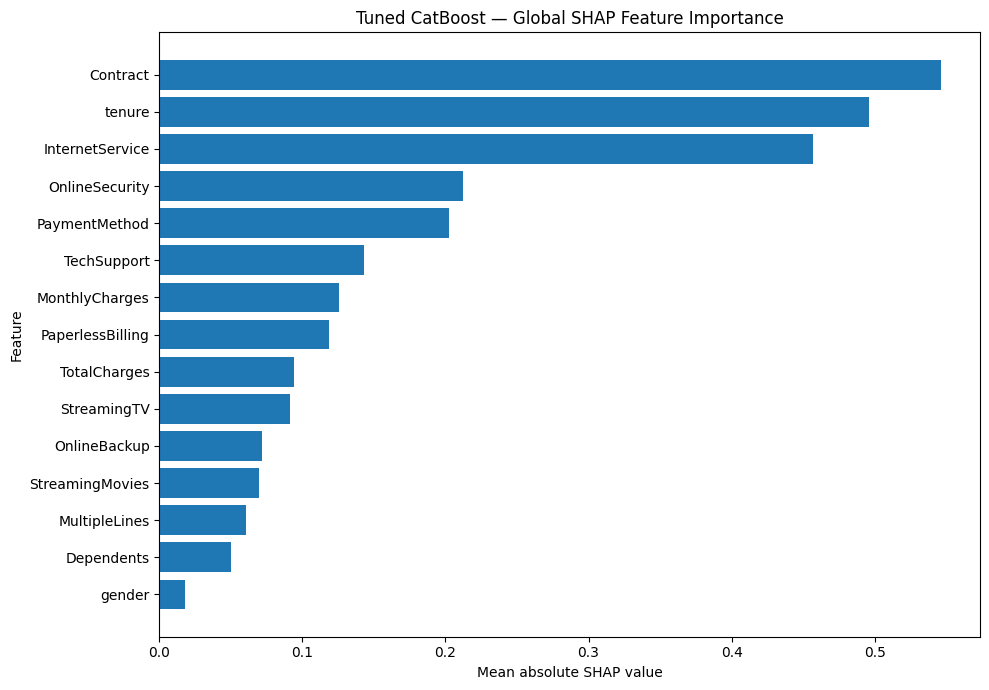


Top 15 features by mean absolute SHAP:


,feature,mean_abs_shap,mean_shap
0,Contract,0.5464,-0.0085
1,tenure,0.4959,-0.0079
2,InternetService,0.4567,0.0353
3,OnlineSecurity,0.2121,0.0137
4,PaymentMethod,0.2023,0.0111
5,TechSupport,0.1428,-0.0233
6,MonthlyCharges,0.1253,0.0023
7,PaperlessBilling,0.1184,0.0130
8,TotalCharges,0.0940,0.0134
9,StreamingTV,0.0916,-0.0090



Saved:
/content/drive/MyDrive/customer-churn-intelligence/results/metrics/tuned_catboost_shap_importance.csv
/content/drive/MyDrive/customer-churn-intelligence/results/tuned_catboost_shap_customer_contributions.csv
/content/drive/MyDrive/customer-churn-intelligence/results/figures/tuned_catboost_shap_importance.png
Elapsed seconds: 2.26


In [31]:

import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostClassifier, Pool

start_time = time.time()

# Load the selected tuned model from persistent Google Drive storage
final_model = CatBoostClassifier()
final_model.load_model(str(MODEL_DIR / "catboost_tuned_candidate.cbm"))

# Explain a reproducible sample of validation customers
X_explain = X_valid.sample(
    n=min(200, len(X_valid)),
    random_state=42
).copy()

explain_pool = Pool(
    X_explain,
    cat_features=cat_features
)

# CatBoost SHAP: last column is the expected/base value
shap_values = final_model.get_feature_importance(
    data=explain_pool,
    type="ShapValues"
)

shap_contributions = shap_values[:, :-1]
base_values = shap_values[:, -1]

# Global feature importance from mean absolute SHAP
shap_importance = pd.DataFrame({
    "feature": X_explain.columns,
    "mean_abs_shap": np.abs(shap_contributions).mean(axis=0),
    "mean_shap": shap_contributions.mean(axis=0)
}).sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

# Save explainability results to Google Drive
shap_csv_path = METRICS_DIR / "tuned_catboost_shap_importance.csv"
shap_importance.to_csv(shap_csv_path, index=False)

# Save the sample-level SHAP values for later customer explanations
shap_detail = pd.DataFrame(
    shap_contributions,
    columns=X_explain.columns,
    index=X_explain.index
)
shap_detail.insert(0, "validation_row_index", X_explain.index)
shap_detail.to_csv(
    RESULTS_DIR / "tuned_catboost_shap_customer_contributions.csv",
    index=False
)

# Plot the top 15 features
top_features = shap_importance.head(15).sort_values("mean_abs_shap")

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["feature"],
    top_features["mean_abs_shap"]
)
plt.xlabel("Mean absolute SHAP value")
plt.ylabel("Feature")
plt.title("Tuned CatBoost — Global SHAP Feature Importance")
plt.tight_layout()

shap_plot_path = FIGURES_DIR / "tuned_catboost_shap_importance.png"
plt.savefig(shap_plot_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close()

# Record basic metadata
shap_metadata = {
    "model": "Tuned CatBoost",
    "data_source": "Validation sample",
    "sample_size": int(len(X_explain)),
    "random_state": 42,
    "shap_scale": "CatBoost raw model output, not probability percentage",
    "elapsed_seconds": round(time.time() - start_time, 2)
}

with open(METRICS_DIR / "tuned_catboost_shap_metadata.json", "w") as f:
    json.dump(shap_metadata, f, indent=2)

print("\nTop 15 features by mean absolute SHAP:")
display(shap_importance.head(15).round(4))

print("\nSaved:")
print(shap_csv_path)
print(RESULTS_DIR / "tuned_catboost_shap_customer_contributions.csv")
print(shap_plot_path)
print("Elapsed seconds:", shap_metadata["elapsed_seconds"])


In [32]:

import numpy as np
import pandas as pd

FINAL_THRESHOLD = 0.30

# Calculate churn probabilities from the tuned model
risk_probabilities = final_model.predict_proba(X_explain)[:, 1]

risk_profiles = pd.DataFrame({
    "validation_row_index": X_explain.index,
    "actual_churn": np.asarray(y_valid.loc[X_explain.index]),
    "churn_probability": risk_probabilities
})

# Apply the documented risk-segment rules
risk_profiles["risk_segment"] = np.select(
    [
        risk_probabilities < FINAL_THRESHOLD,
        risk_probabilities <= 0.60
    ],
    [
        "Low",
        "Medium"
    ],
    default="High"
)

# Add customer features for business interpretation
risk_profiles = pd.concat(
    [
        risk_profiles.reset_index(drop=True),
        X_explain.reset_index(drop=True)
    ],
    axis=1
)

# Find each customer's strongest positive and negative SHAP contributions
shap_feature_names = list(X_explain.columns)

positive_reasons = []
negative_reasons = []

for row in shap_contributions:
    positive_indices = np.argsort(row)[::-1]
    negative_indices = np.argsort(row)

    positive_reasons.append(
        ", ".join(
            f"{shap_feature_names[i]} (+{row[i]:.3f})"
            for i in positive_indices
            if row[i] > 0
        )[:250]
    )

    negative_reasons.append(
        ", ".join(
            f"{shap_feature_names[i]} ({row[i]:.3f})"
            for i in negative_indices
            if row[i] < 0
        )[:250]
    )

risk_profiles["strongest_positive_shap_reasons"] = positive_reasons
risk_profiles["strongest_negative_shap_reasons"] = negative_reasons

# Save customer-level profiles
risk_path = RESULTS_DIR / "tuned_catboost_customer_risk_profiles.csv"
risk_profiles.to_csv(risk_path, index=False)

# Summarize risk segments
risk_summary = (
    risk_profiles.groupby("risk_segment")
    .agg(
        customers=("churn_probability", "size"),
        mean_predicted_churn_probability=("churn_probability", "mean"),
        actual_churn_rate=("actual_churn", "mean")
    )
    .reset_index()
)

risk_summary_path = METRICS_DIR / "tuned_catboost_risk_segment_summary.csv"
risk_summary.to_csv(risk_summary_path, index=False)

print("Risk-segment summary:")
display(risk_summary.round(4))

print("\nSample customer profiles:")
display(
    risk_profiles[
        [
            "validation_row_index",
            "churn_probability",
            "risk_segment",
            "actual_churn",
            "strongest_positive_shap_reasons",
            "strongest_negative_shap_reasons"
        ]
    ].head(10)
)

print("\nSaved customer profiles:", risk_path)
print("Saved risk summary:", risk_summary_path)


Risk-segment summary:


,risk_segment,customers,mean_predicted_churn_probability,actual_churn_rate
0,High,29,0.7233,0.7241
1,Low,127,0.1029,0.0787
2,Medium,44,0.4389,0.5455



Sample customer profiles:


,validation_row_index,churn_probability,risk_segment,actual_churn,strongest_positive_shap_reasons,strongest_negative_shap_reasons
0,6011,0.066634,Low,0,"Contract (+0.743), PaymentMethod (+0.218), Pho...","tenure (-0.439), InternetService (-0.432), Str..."
1,2064,0.021718,Low,0,"TotalCharges (+0.040), gender (+0.007), PhoneS...","InternetService (-0.473), Contract (-0.432), t..."
2,6423,0.007945,Low,0,MultipleLines (+0.004),"Contract (-0.753), tenure (-0.729), InternetSe..."
3,680,0.760339,High,1,"tenure (+1.197), InternetService (+0.589), Con...","PaperlessBilling (-0.213), MultipleLines (-0.1..."
4,14,0.482621,Medium,0,"InternetService (+0.517), Contract (+0.493), M...","tenure (-0.213), OnlineSecurity (-0.165), Tech..."
5,359,0.252819,Low,0,"InternetService (+0.562), PaymentMethod (+0.35...","Contract (-0.471), tenure (-0.287), PaperlessB..."
6,5474,0.878892,High,0,"tenure (+1.222), InternetService (+0.596), Con...","StreamingMovies (-0.066), SeniorCitizen (-0.01..."
7,4226,0.707364,High,1,"tenure (+0.688), InternetService (+0.562), Con...","StreamingMovies (-0.084), MonthlyCharges (-0.0..."
8,4887,0.052502,Low,0,"Contract (+0.742), PhoneService (+0.000)","tenure (-0.445), InternetService (-0.437), Str..."
9,154,0.130906,Low,0,"tenure (+0.596), Contract (+0.552), TotalCharg...","InternetService (-0.439), StreamingTV (-0.252)..."



Saved customer profiles: /content/drive/MyDrive/customer-churn-intelligence/results/tuned_catboost_customer_risk_profiles.csv
Saved risk summary: /content/drive/MyDrive/customer-churn-intelligence/results/metrics/tuned_catboost_risk_segment_summary.csv


In [33]:

import numpy as np
import pandas as pd

# Build a customer-friendly explanation table from the existing
# tuned-model validation sample and SHAP contributions.

explanations = []

for row_pos, (_, customer) in enumerate(X_explain.iterrows()):
    contributions = shap_contributions[row_pos]

    # Strongest positive and negative feature contributions
    positive_idx = np.argsort(contributions)[::-1]
    negative_idx = np.argsort(contributions)

    positive_idx = [i for i in positive_idx if contributions[i] > 0][:3]
    negative_idx = [i for i in negative_idx if contributions[i] < 0][:3]

    def describe_features(indices):
        descriptions = []
        for i in indices:
            feature = X_explain.columns[i]
            value = customer[feature]
            contribution = contributions[i]
            descriptions.append(
                f"{feature}={value} (SHAP {contribution:+.3f})"
            )
        return "; ".join(descriptions) if descriptions else "None"

    probability = float(risk_probabilities[row_pos])

    explanations.append({
        "validation_row_index": X_explain.index[row_pos],
        "actual_churn": int(y_valid.loc[X_explain.index[row_pos]]),
        "predicted_churn_probability": probability,
        "risk_segment": (
            "Low" if probability < 0.30
            else "Medium" if probability <= 0.60
            else "High"
        ),
        "Contract": customer["Contract"],
        "tenure_months": customer["tenure"],
        "InternetService": customer["InternetService"],
        "OnlineSecurity": customer["OnlineSecurity"],
        "TechSupport": customer["TechSupport"],
        "strongest_positive_contributors": describe_features(positive_idx),
        "strongest_negative_contributors": describe_features(negative_idx)
    })

explanation_df = pd.DataFrame(explanations)

explanation_path = RESULTS_DIR / "customer_explanations_business_friendly.csv"
explanation_df.to_csv(explanation_path, index=False)

print("Customer explanations — first 10 rows:")
display(explanation_df.head(10).round(4))

print("\nRisk segment counts:")
display(
    explanation_df.groupby("risk_segment")
    .agg(
        customers=("validation_row_index", "size"),
        mean_predicted_probability=("predicted_churn_probability", "mean"),
        observed_churn_rate=("actual_churn", "mean")
    )
    .reset_index()
    .round(4)
)

print("\nSaved:", explanation_path)
print(
    "\nNote: SHAP contributions explain the model's raw output; "
    "they are not percentage-point changes or causal explanations."
)


Customer explanations — first 10 rows:


,validation_row_index,actual_churn,predicted_churn_probability,risk_segment,Contract,tenure_months,InternetService,OnlineSecurity,TechSupport,strongest_positive_contributors,strongest_negative_contributors
0,6011,0,0.0666,Low,Month-to-month,37,No,No internet service,No internet service,Contract=Month-to-month (SHAP +0.743); Payment...,tenure=37 (SHAP -0.439); InternetService=No (S...
1,2064,0,0.0217,Low,One year,30,No,No internet service,No internet service,TotalCharges=608.5 (SHAP +0.040); gender=Femal...,InternetService=No (SHAP -0.473); Contract=One...
2,6423,0,0.0079,Low,Two year,72,No,No internet service,No internet service,MultipleLines=Yes (SHAP +0.004),Contract=Two year (SHAP -0.753); tenure=72 (SH...
3,680,1,0.7603,High,Month-to-month,1,Fiber optic,No,No,tenure=1 (SHAP +1.197); InternetService=Fiber ...,PaperlessBilling=No (SHAP -0.213); MultipleLin...
4,14,0,0.4826,Medium,Month-to-month,25,Fiber optic,Yes,Yes,InternetService=Fiber optic (SHAP +0.517); Con...,tenure=25 (SHAP -0.213); OnlineSecurity=Yes (S...
5,359,0,0.2528,Low,One year,42,Fiber optic,Yes,No,InternetService=Fiber optic (SHAP +0.562); Pay...,Contract=One year (SHAP -0.471); tenure=42 (SH...
6,5474,0,0.8789,High,Month-to-month,1,Fiber optic,No,No,tenure=1 (SHAP +1.222); InternetService=Fiber ...,StreamingMovies=No (SHAP -0.066); SeniorCitize...
7,4226,1,0.7074,High,Month-to-month,3,Fiber optic,No,No,tenure=3 (SHAP +0.688); InternetService=Fiber ...,StreamingMovies=No (SHAP -0.084); MonthlyCharg...
8,4887,0,0.0525,Low,Month-to-month,38,No,No internet service,No internet service,Contract=Month-to-month (SHAP +0.742); PhoneSe...,tenure=38 (SHAP -0.445); InternetService=No (S...
9,154,0,0.1309,Low,Month-to-month,6,No,No internet service,No internet service,tenure=6 (SHAP +0.596); Contract=Month-to-mont...,InternetService=No (SHAP -0.439); StreamingTV=...



Risk segment counts:


,risk_segment,customers,mean_predicted_probability,observed_churn_rate
0,High,29,0.7233,0.7241
1,Low,127,0.1029,0.0787
2,Medium,44,0.4389,0.5455



Saved: /content/drive/MyDrive/customer-churn-intelligence/results/customer_explanations_business_friendly.csv

Note: SHAP contributions explain the model's raw output; they are not percentage-point changes or causal explanations.


In [34]:

from pathlib import Path
import json
import pandas as pd

# Load saved final metrics and SHAP results
with open(METRICS_DIR / "final_test_metrics.json") as f:
    test_report = json.load(f)

with open(MODEL_DIR / "catboost_tuned_config.json") as f:
    tuned_config = json.load(f)

shap_report = pd.read_csv(
    METRICS_DIR / "tuned_catboost_shap_importance.csv"
)

risk_report = pd.read_csv(
    METRICS_DIR / "tuned_catboost_risk_segment_summary.csv"
)

test_cm = test_report["confusion_matrix"]

report = f"""# Customer Churn Prediction & Retention Intelligence System

## 1. Project Overview

This project predicts customer churn using the IBM Telco Customer Churn dataset.
It combines exploratory data analysis, preprocessing, baseline model comparison,
CatBoost tuning, threshold analysis, SHAP explainability, and customer risk segmentation.

## 2. Business Problem

Customer churn can reduce recurring revenue. A predictive model can help prioritize
customers for retention outreach. Model predictions are risk estimates, not guarantees
that a customer will leave or that an intervention will prevent churn.

## 3. Dataset and Data Quality

- Original dataset: 7,043 rows and 21 columns.
- Target: Churn (Yes/No).
- Original churn rate: approximately 26.54%.
- Eleven blank TotalCharges values were found among customers with zero tenure.
- Those values were converted to numeric and filled with zero under a documented assumption.
- customerID was excluded from model features.
- No rows were dropped during cleaning.

## 4. Exploratory Data Analysis

Observed churn rates:

- Month-to-month contract: 42.71%.
- One-year contract: 11.27%.
- Two-year contract: 2.83%.
- Tenure 0-12 months: 47.44%.
- Tenure 49-72 months: 9.51%.
- Electronic check payment: 45.29%.

These are associations in this dataset and do not establish causal effects.

## 5. Modeling and Validation

Four baseline models were evaluated using a validation set:
Logistic Regression, Random Forest, Gradient Boosting, and CatBoost.

The selected tuned CatBoost configuration was chosen by validation ROC-AUC.

- Depth: {tuned_config["depth"]}
- Learning rate: {tuned_config["learning_rate"]}
- L2 regularization: {tuned_config["l2_leaf_reg"]}
- Best iteration: {tuned_config["best_iteration"]}
- Validation ROC-AUC: {tuned_config["validation_roc_auc"]:.4f}

The decision threshold was selected using validation data, with 0.30 chosen
as the F1-leading threshold among those tested.

## 6. Final Test Results

- Accuracy: {test_report["test_accuracy"]:.4f}
- Balanced accuracy: {test_report["test_balanced_accuracy"]:.4f}
- Precision: {test_report["test_precision"]:.4f}
- Recall: {test_report["test_recall"]:.4f}
- F1 score: {test_report["test_f1"]:.4f}
- ROC-AUC: {test_report["test_roc_auc"]:.4f}
- Decision threshold: {test_report["selected_threshold"]:.2f}
- Test customers flagged: {test_report["customers_targeted"]}
- Percentage flagged: {test_report["targeted_percentage"]:.2f}%

Confusion matrix (actual rows: no churn, churn; predicted columns: no churn, churn):

| | Predicted no churn | Predicted churn |
|---|---:|---:|
| Actual no churn | {test_cm["true_negatives"]} | {test_cm["false_positives"]} |
| Actual churn | {test_cm["false_negatives"]} | {test_cm["true_positives"]} |

The test set was reserved for final evaluation after model and threshold selection.
Test results were not used to choose the model or threshold.

## 7. Model Explainability

Global SHAP importance was calculated on a sample of 200 validation customers.

Top features by mean absolute SHAP value:

{chr(10).join(
    f"- {row.feature}: {row.mean_abs_shap:.4f}"
    for row in shap_report.head(10).itertuples()
)}

SHAP contributions explain the model's raw output and are not percentage-point
changes in probability or causal explanations.

## 8. Customer Risk Segmentation

Risk segments were created for a sample of 200 validation customers:

{risk_report.to_markdown(index=False)}

- Low risk: predicted probability below 0.30.
- Medium risk: predicted probability from 0.30 through 0.60.
- High risk: predicted probability above 0.60.

These segment summaries are based on a sample, not the entire customer population.
Predicted probabilities have not been established as calibrated probabilities.

## 9. Limitations

- This is a public historical dataset, not live company data.
- Validation and test metrics may differ due to sampling variability.
- The 0.30 threshold was chosen using validation F1, not measured retention economics.
- False positives may incur outreach costs; false negatives may represent missed opportunities.
- Predictive associations do not prove causes of churn.
- No causal evidence establishes that a retention offer will prevent churn.
- The risk-segment summary uses a 200-customer validation sample.

## 10. Reproducibility and Saved Artifacts

The project stores data, models, metrics, figures, and customer explanations in Google Drive.

Key artifacts include:

- data/telco_churn_cleaned.csv
- artifacts/models/catboost_tuned_candidate.cbm
- artifacts/models/catboost_tuned_config.json
- results/metrics/final_test_metrics.json
- results/metrics/tuned_catboost_shap_importance.csv
- results/tuned_catboost_customer_risk_profiles.csv
- results/customer_explanations_business_friendly.csv
- results/final_test_predictions.csv

## 11. Conclusion

The tuned CatBoost model achieved a test ROC-AUC of {test_report["test_roc_auc"]:.4f}
and churn recall of {test_report["test_recall"]:.4f} at the selected threshold.
The project demonstrates a reproducible classification workflow, threshold trade-off
analysis, model explainability, and risk segmentation. Further business validation
would be required before deploying it for real retention decisions.
"""

report_path = PROJECT_DIR / "FINAL_PROJECT_REPORT.md"
report_path.write_text(report, encoding="utf-8")

print("Final report created:")
print(report_path)
print("\nPreview:")
print(report[:2500])


Final report created:
/content/drive/MyDrive/customer-churn-intelligence/FINAL_PROJECT_REPORT.md

Preview:
# Customer Churn Prediction & Retention Intelligence System

## 1. Project Overview

This project predicts customer churn using the IBM Telco Customer Churn dataset.
It combines exploratory data analysis, preprocessing, baseline model comparison,
CatBoost tuning, threshold analysis, SHAP explainability, and customer risk segmentation.

## 2. Business Problem

Customer churn can reduce recurring revenue. A predictive model can help prioritize
customers for retention outreach. Model predictions are risk estimates, not guarantees
that a customer will leave or that an intervention will prevent churn.

## 3. Dataset and Data Quality

- Original dataset: 7,043 rows and 21 columns.
- Target: Churn (Yes/No).
- Original churn rate: approximately 26.54%.
- Eleven blank TotalCharges values were found among customers with zero tenure.
- Those values were converted to numeric and filled with z